<img src="https://www.pucsp.br/sites/default/files/download/brasao-PUCSP-assinatura-principal-RGB.png" style="float:right;" width="150px">

# Ciências da Computação [》](https://www.pucsp.br/graduacao/ciencia-da-computacao)

## Inteligência Artificial — IA ML Cluster (Não Supervisionada)
### LAB - Mini Projeto: Segmentação de Clientes de Cartão de Crédito (K-Means)

**Aluno:**
* Pedro Evaristo de Oliveira

---

### 1. Introdução e Objetivo
Neste mini projeto de aprendizagem não supervisionada, é utilizado o algoritmo **K-Means** da biblioteca `scikit-learn` para realizar a segmentação de clientes com base no seu comportamento de uso de cartão de crédito.

Os dados foram extraídos do Kaggle (**Credit Card Dataset for Clustering**) e contêm o histórico de transações, saldos e limites de cerca de 9.000 clientes. A segmentação (Clustering) permite a criação de perfis de consumidores, o que é essencial para a definição de estratégias de marketing direcionadas no setor bancário.

In [4]:
# Importação das bibliotecas necessárias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# Configuração visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

### 2. Análise Exploratória de Dados (EDA) e Limpeza
Após o carregamento do dataset, analisa-se a distribuição das variáveis. Como o K-Means se baseia em distâncias (Euclidiana), é imperativo tratar valores nulos e remover atributos não numéricos (como o ID do cliente).

In [5]:
# Carregamento dos dados (tentando primeiro na pasta 'sample_data' padrão do Colab)
try:
    df = pd.read_csv('sample_data/CC GENERAL.csv')
    print(f"Dataset carregado com sucesso! Dimensões: {df.shape[0]} linhas e {df.shape[1]} colunas.")
except FileNotFoundError:
    try:
        df = pd.read_csv('CC GENERAL.csv')
        print(f"Dataset carregado com sucesso! Dimensões: {df.shape[0]} linhas e {df.shape[1]} colunas.")
    except FileNotFoundError:
        print("ERRO: O ficheiro 'CC GENERAL.csv' não foi encontrado. Por favor, faça o upload no Colab.")
        df = None

if df is not None:
    display(df.head())


Dataset carregado com sucesso! Dimensões: 8950 linhas e 18 colunas.


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


Valores Nulos por Coluna antes da limpeza:
CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64


/tmp/ipykernel_1503/1006340686.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['MINIMUM_PAYMENTS'].fillna(df['MINIMUM_PAYMENTS'].median(), inplace=True)
/tmp/ipykernel_1503/1006340686.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method

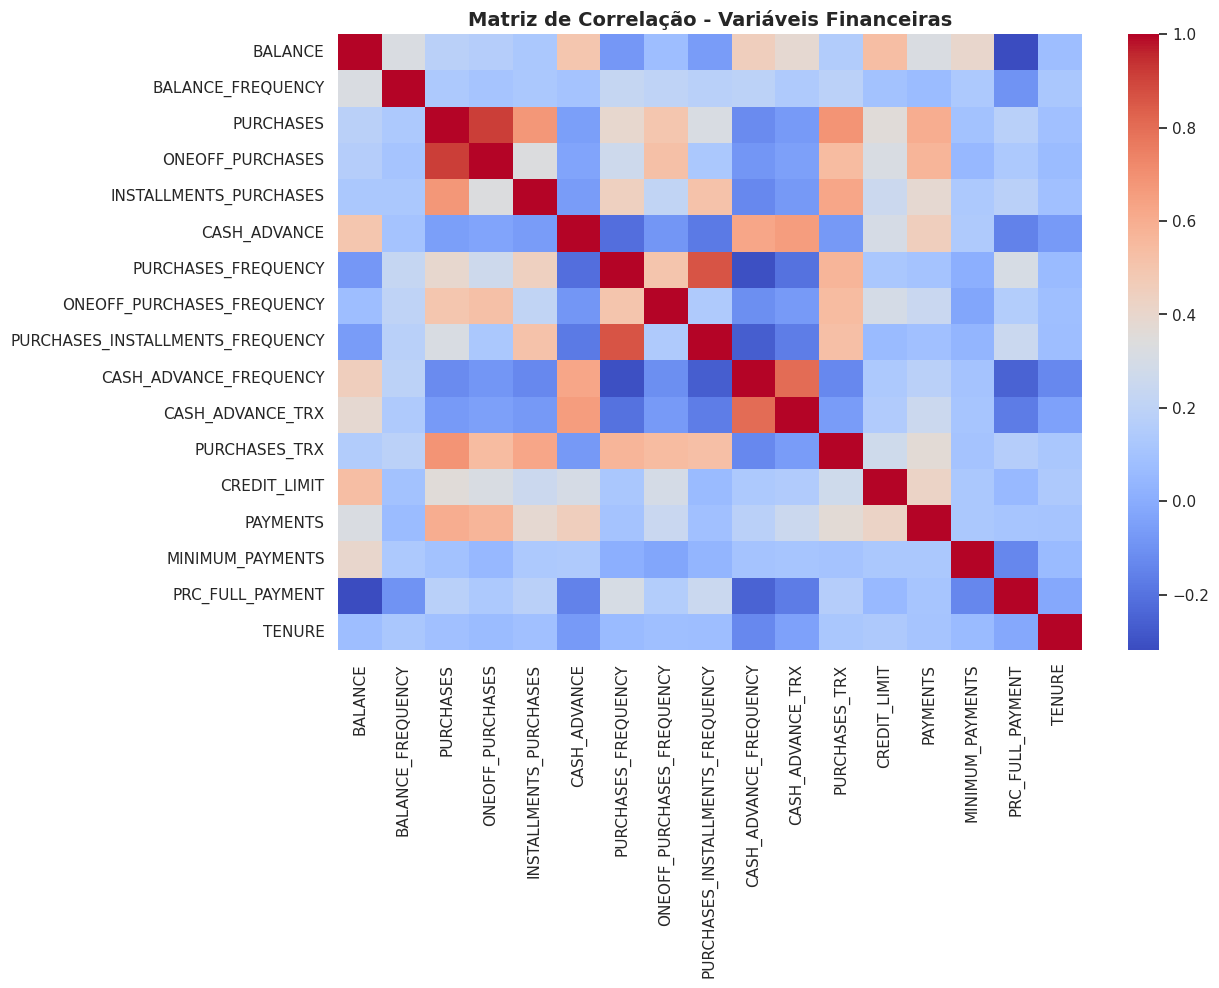

In [6]:
# Tratamento de Valores Nulos
print("Valores Nulos por Coluna antes da limpeza:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Preencher valores ausentes com a mediana (abordagem robusta a outliers)
df['MINIMUM_PAYMENTS'].fillna(df['MINIMUM_PAYMENTS'].median(), inplace=True)
df['CREDIT_LIMIT'].fillna(df['CREDIT_LIMIT'].median(), inplace=True)

# Remover a coluna CUST_ID (string que não é útil para cálculos de distância)
df_cluster = df.drop('CUST_ID', axis=1)

# Matriz de Correlação para Análise Exploratória
plt.figure(figsize=(12, 8))
sns.heatmap(df_cluster.corr(), cmap='coolwarm', fmt=".1f", annot=False)
plt.title("Matriz de Correlação - Variáveis Financeiras", fontsize=14, fontweight='bold')
plt.show()

### 3. Escalonamento dos Dados (StandardScaler)
Algoritmos baseados em distâncias requerem que todas as variáveis estejam na mesma escala (média 0 e variância 1).

In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_cluster)
print("Dados escalonados com sucesso.")

Dados escalonados com sucesso.


### 4. Modelação: K-Means e Escolha do Número de Clusters (k)
Utiliza-se o **Método do Cotovelo (Elbow Method)** para determinar o número ideal de clusters, medindo a soma dos quadrados das distâncias intra-cluster (WCSS/Inertia).

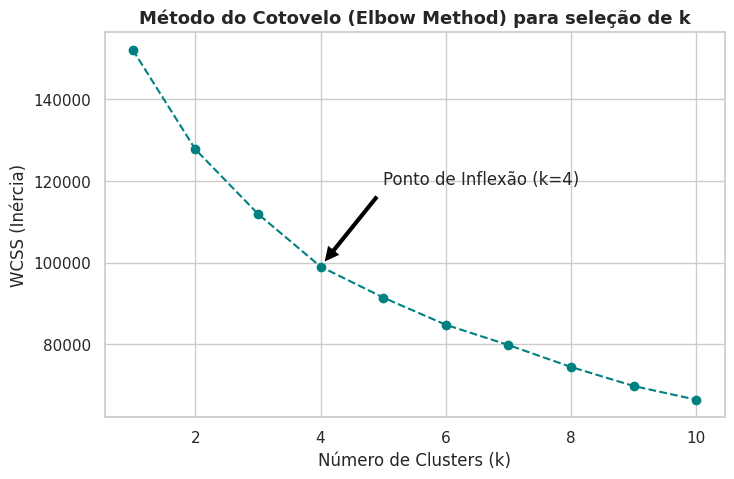

In [8]:
wcss = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_range, wcss, marker='o', linestyle='--', color='teal')
plt.title('Método do Cotovelo (Elbow Method) para seleção de k', fontsize=13, fontweight='bold')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('WCSS (Inércia)')
plt.annotate('Ponto de Inflexão (k=4)', xy=(4, wcss[3]), xytext=(5, wcss[3] + 20000),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.show()

### 5. Aplicação do Modelo Final e Redução de Dimensionalidade (PCA)
Fixando `k=4`. Como existem 17 variáveis, é impossível visualizar os clusters num plano 2D. Recorre-se ao **PCA (Principal Component Analysis)** para reduzir as 17 dimensões para apenas 2, retendo a maior parte da variância dos dados para efeitos de visualização.

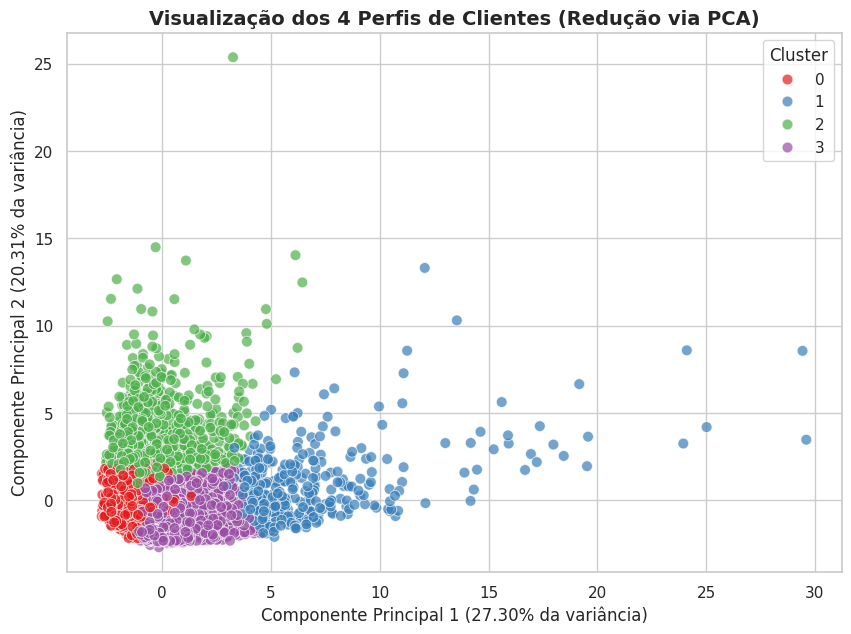

In [9]:
# 1. Treino do K-Means com k=4
kmeans_final = KMeans(n_clusters=4, init='k-means++', random_state=42, n_init=10)
clusters = kmeans_final.fit_predict(X_scaled)

# Adicionar os rótulos ao dataframe original
df['Cluster'] = clusters

# 2. Aplicação do PCA para visualização em 2D
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

df_pca = pd.DataFrame(data=X_pca, columns=['Componente 1', 'Componente 2'])
df_pca['Cluster'] = clusters

# 3. Gráfico de Dispersão dos Clusters
plt.figure(figsize=(10, 7))
sns.scatterplot(x='Componente 1', y='Componente 2', hue='Cluster', data=df_pca, palette='Set1', s=60, alpha=0.7)
plt.title('Visualização dos 4 Perfis de Clientes (Redução via PCA)', fontsize=14, fontweight='bold')
plt.xlabel(f'Componente Principal 1 ({pca.explained_variance_ratio_[0]:.2%} da variância)')
plt.ylabel(f'Componente Principal 2 ({pca.explained_variance_ratio_[1]:.2%} da variância)')
plt.legend(title='Cluster')
plt.show()

### 6. Conclusão e Análise de Negócio
Após o agrupamento dos clientes através do K-Means, é possível inferir o perfil financeiro de cada Cluster através das suas médias:
* **Cluster 0:** Clientes que pagam o saldo na totalidade, utilizam muito para compras pontuais (Perfil "Transactor").
* **Cluster 1:** Clientes com saldos elevados e muitos adiantamentos em dinheiro (*Cash Advance*), com pagamentos mínimos baixos (Perfil "Revolver / Alto Risco").
* **Cluster 2:** Clientes inativos ou mais económicos, com saldos e limites baixos e poucas compras efetuadas.
* **Cluster 3:** Clientes *Premium*, limites de crédito extremamente altos e um elevado volume de transações em compras (Alta rentabilidade para o banco).